# RiceVision AI
# Notebook 02: Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to perform an in-depth exploratory data analysis of the Rice Leaf Disease dataset.

This notebook will help us understand the characteristics of the dataset before preprocessing and model training.

The analysis includes:

- Class distribution
- Sample image visualization
- Image dimension analysis
- Aspect ratio analysis
- RGB channel statistics
- Pixel intensity distribution
- Brightness analysis
- Color histogram analysis
- Image entropy analysis
- Outlier detection
- Data augmentation preview

The insights gained will help in designing an effective preprocessing and deep learning pipeline.

In [3]:
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

plt.style.use("ggplot")

In [4]:
# ==========================================
# Project Paths
# ==========================================

PROJECT_ROOT = Path("..")

DATASET_PATH = PROJECT_ROOT / "Rice Leaf Disease Images"

OUTPUT_PATH = PROJECT_ROOT / "outputs"

FIGURE_PATH = OUTPUT_PATH / "figures"

REPORT_PATH = OUTPUT_PATH / "reports"

classes = sorted(
    [
        folder.name
        for folder in DATASET_PATH.iterdir()
        if folder.is_dir()
    ]
)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [5]:
records = []

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

for cls in classes:

    folder = DATASET_PATH / cls

    for image_path in folder.glob("*"):

        if image_path.suffix.lower() in IMAGE_EXTENSIONS:

            image = Image.open(image_path)

            width, height = image.size

            records.append({

                "Class": cls,

                "Path": str(image_path),

                "Width": width,

                "Height": height,

                "Aspect Ratio": width / height

            })

eda_df = pd.DataFrame(records)

eda_df.head()

,Class,Path,Width,Height,Aspect Ratio
0,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0
1,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0
2,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0
3,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0
4,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0


In [6]:
print(f"Total Images : {len(eda_df)}")
print(f"Number of Classes : {eda_df['Class'].nunique()}")

Total Images : 5932
Number of Classes : 4


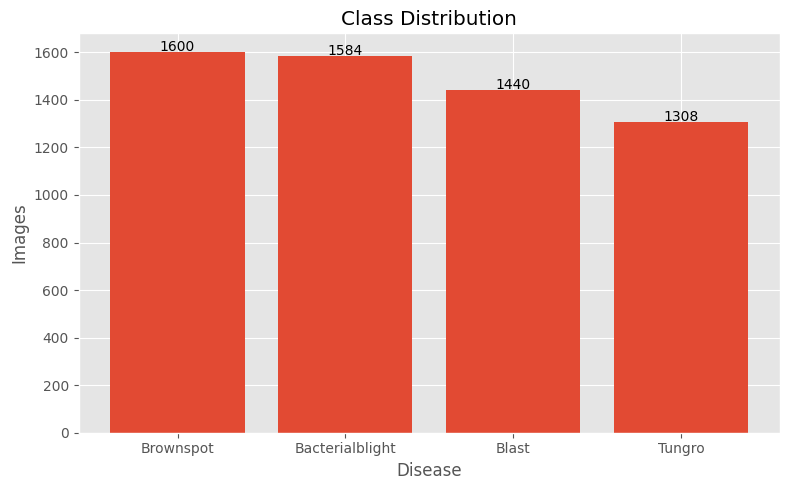

In [7]:
class_counts = eda_df["Class"].value_counts()

plt.figure(figsize=(8,5))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Class Distribution")

plt.xlabel("Disease")

plt.ylabel("Images")

for bar in bars:

    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+5,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_PATH/"eda_class_distribution.png",
    dpi=300
)

plt.show()

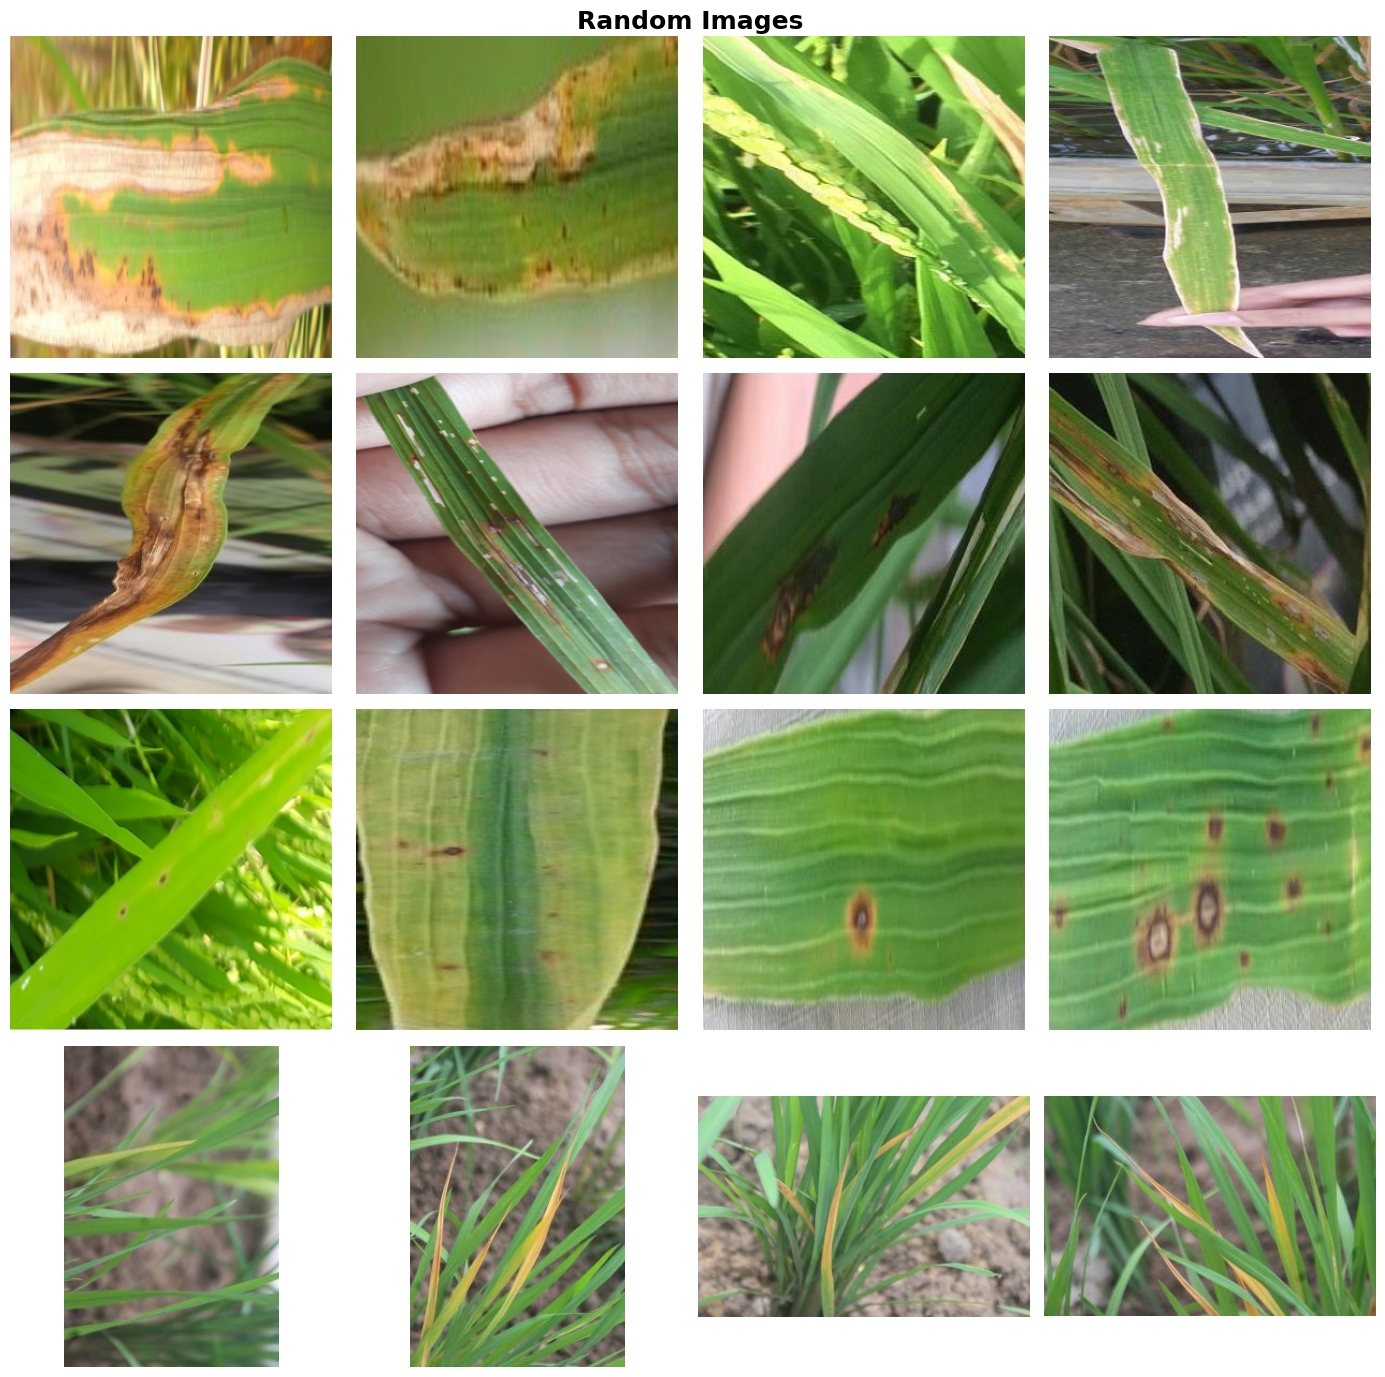

In [8]:
fig, axes = plt.subplots(4,4, figsize=(14,14))

fig.suptitle(
    "Random Images",
    fontsize=18,
    fontweight="bold"
)

for row, cls in enumerate(classes):

    folder = DATASET_PATH / cls

    images = list(folder.glob("*"))

    samples = random.sample(images,4)

    for col, img_path in enumerate(samples):

        image = Image.open(img_path)

        axes[row,col].imshow(image)

        axes[row,col].axis("off")

        if col==0:
            axes[row,col].set_ylabel(cls)

plt.tight_layout()

plt.show()

In [9]:
eda_df[["Width","Height"]].describe()

,Width,Height
count,5932.000000,5932.000000
mean,312.243763,312.203641
std,53.418987,53.445428
min,209.000000,209.000000
25%,300.000000,300.000000
50%,300.000000,300.000000
75%,300.000000,300.000000
max,603.000000,603.000000


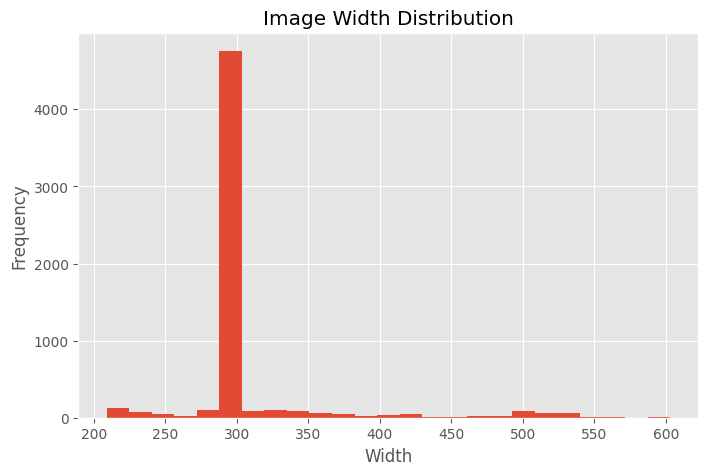

In [10]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Width"],
    bins=25
)

plt.xlabel("Width")

plt.ylabel("Frequency")

plt.title("Image Width Distribution")

plt.show()

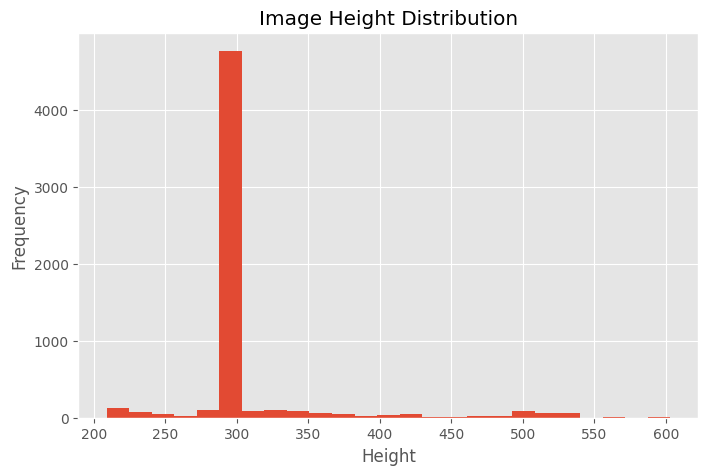

In [11]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Height"],
    bins=25
)

plt.xlabel("Height")

plt.ylabel("Frequency")

plt.title("Image Height Distribution")

plt.show()

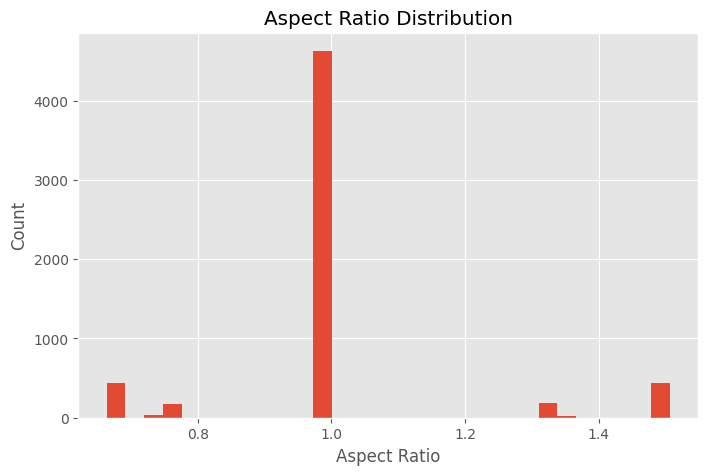

In [12]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Aspect Ratio"],
    bins=30
)

plt.xlabel("Aspect Ratio")

plt.ylabel("Count")

plt.title("Aspect Ratio Distribution")

plt.show()

In [13]:
# ==========================================
# RGB Channel Statistics
# ==========================================

rgb_stats = []

for img_path in tqdm(eda_df["Path"], desc="Computing RGB Statistics"):

    image = cv2.imread(img_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    rgb_stats.append({

        "R": image[:,:,0].mean(),

        "G": image[:,:,1].mean(),

        "B": image[:,:,2].mean()

    })

rgb_df = pd.DataFrame(rgb_stats)

rgb_df.head()

Computing RGB Statistics: 100%|███████████████████████████████████████████████████| 5932/5932 [00:10<00:00, 589.47it/s]


,R,G,B
0,99.807000,135.254811,31.044689
1,99.809533,135.262444,31.049833
2,109.579178,151.613433,58.821111
3,109.562233,151.618344,58.859022
4,124.389411,167.937100,71.273100


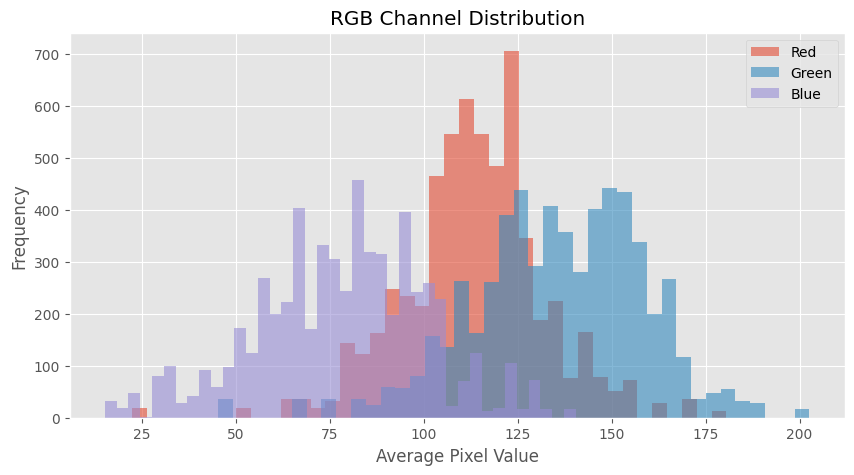

In [14]:
plt.figure(figsize=(10,5))

plt.hist(rgb_df["R"], bins=40, alpha=0.6, label="Red")

plt.hist(rgb_df["G"], bins=40, alpha=0.6, label="Green")

plt.hist(rgb_df["B"], bins=40, alpha=0.6, label="Blue")

plt.title("RGB Channel Distribution")

plt.xlabel("Average Pixel Value")

plt.ylabel("Frequency")

plt.legend()

plt.savefig(
    FIGURE_PATH / "rgb_distribution.png",
    dpi=300
)

plt.show()

In [15]:
brightness = []

for img_path in tqdm(eda_df["Path"], desc="Brightness Analysis"):

    image = cv2.imread(img_path)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness.append(gray.mean())

eda_df["Brightness"] = brightness

eda_df.head()

Brightness Analysis: 100%|████████████████████████████████████████████████████████| 5932/5932 [00:08<00:00, 687.26it/s]


,Class,Path,Width,Height,Aspect Ratio,Brightness
0,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0,112.769333
1,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0,112.774433
2,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0,128.463900
3,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0,128.467233
4,Bacterialblight,..\Rice Leaf Disease Images\Bacterialblight\BA...,300,300,1.0,143.890744


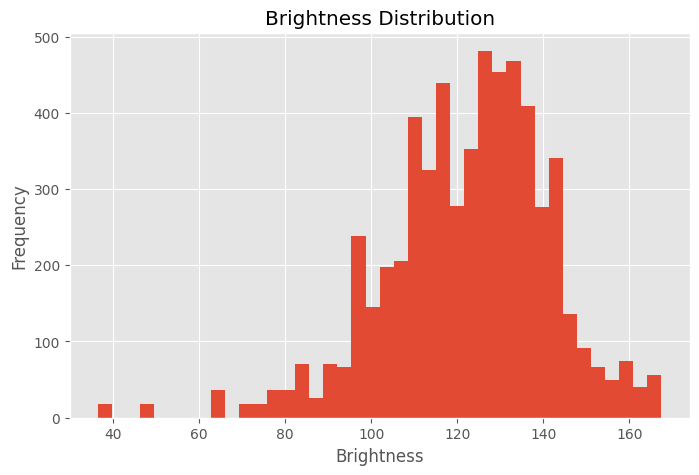

In [16]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Brightness"],
    bins=40
)

plt.title("Brightness Distribution")

plt.xlabel("Brightness")

plt.ylabel("Frequency")

plt.savefig(
    FIGURE_PATH / "brightness_distribution.png",
    dpi=300
)

plt.show()

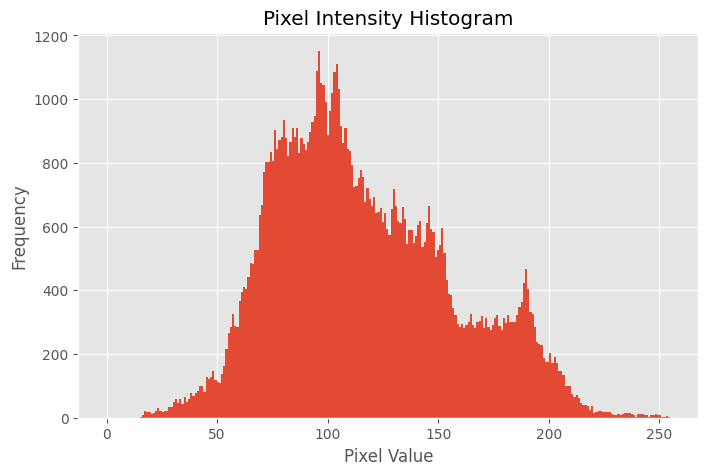

In [17]:
sample_path = random.choice(eda_df["Path"].tolist())

image = cv2.imread(sample_path)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8,5))

plt.hist(
    gray.ravel(),
    bins=256,
    range=(0,255)
)

plt.title("Pixel Intensity Histogram")

plt.xlabel("Pixel Value")

plt.ylabel("Frequency")

plt.show()

In [18]:
from skimage.measure import shannon_entropy

entropy = []

for img_path in tqdm(eda_df["Path"], desc="Entropy"):

    image = cv2.imread(img_path)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    entropy.append(shannon_entropy(gray))

eda_df["Entropy"] = entropy

Entropy: 100%|████████████████████████████████████████████████████████████████████| 5932/5932 [00:35<00:00, 167.09it/s]


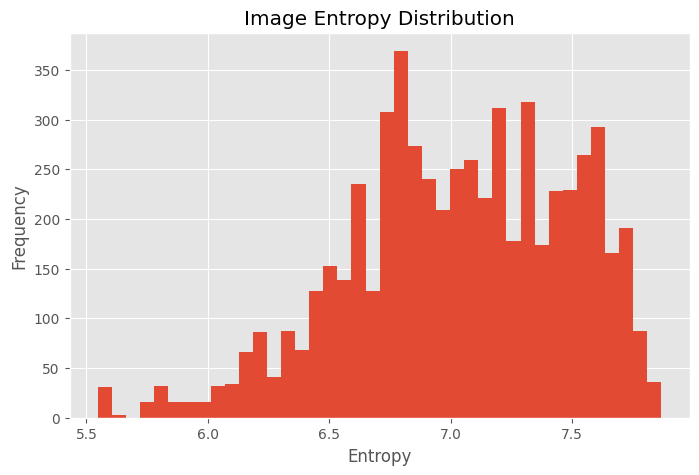

In [19]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Entropy"],
    bins=40
)

plt.title("Image Entropy Distribution")

plt.xlabel("Entropy")

plt.ylabel("Frequency")

plt.show()

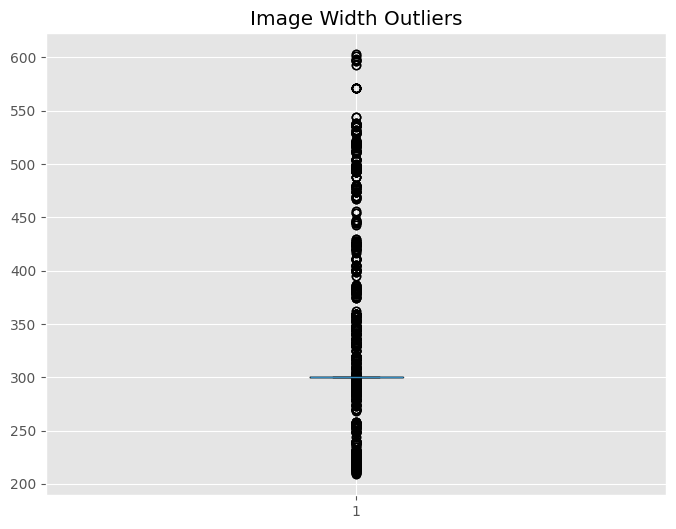

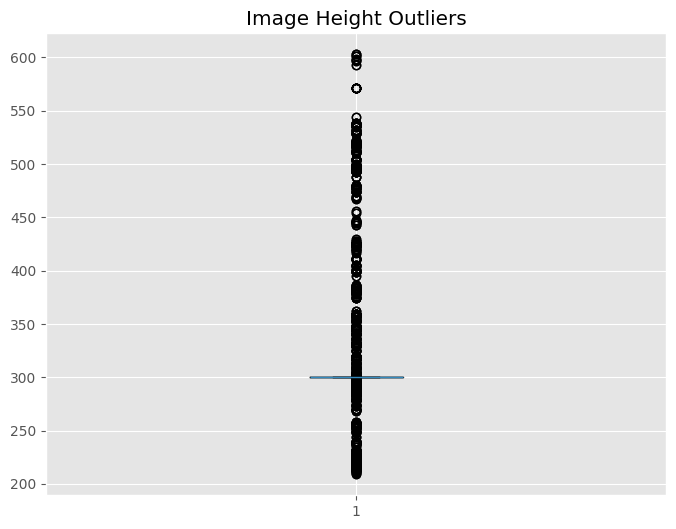

In [20]:
plt.figure(figsize=(8,6))

plt.boxplot(
    eda_df["Width"],
    vert=True
)

plt.title("Image Width Outliers")

plt.show()

plt.figure(figsize=(8,6))

plt.boxplot(
    eda_df["Height"],
    vert=True
)

plt.title("Image Height Outliers")

plt.show()

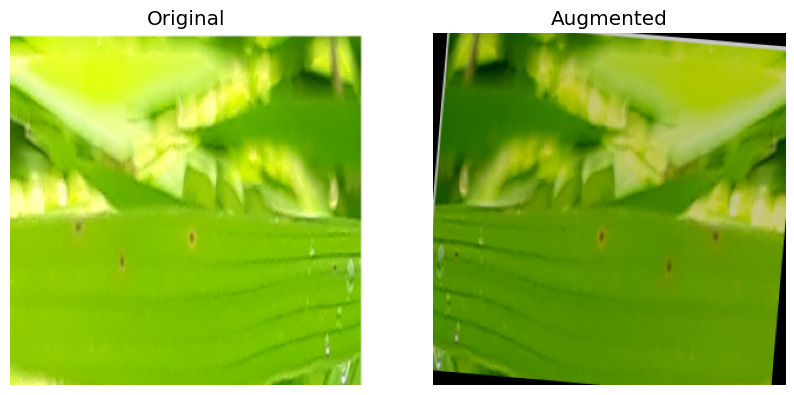

In [21]:
import albumentations as A
import random

transform = A.Compose([
    A.HorizontalFlip(p=1),
    A.RandomBrightnessContrast(p=1),
    A.Rotate(limit=30, p=1)
])

image_path = random.choice(eda_df["Path"].tolist())

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

augmented = transform(image=image)["image"]

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)

plt.imshow(image)

plt.title("Original")

plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(augmented)

plt.title("Augmented")

plt.axis("off")

plt.show()

In [22]:
eda_df.to_csv(
    REPORT_PATH / "eda_summary.csv",
    index=False
)

print("EDA summary saved successfully.")

EDA summary saved successfully.


# Notebook Summary

## Completed Analysis

In this notebook, we performed a comprehensive exploratory data analysis of the Rice Leaf Disease dataset.

### Dataset Exploration
- Loaded and structured metadata for all images.
- Analyzed class distribution.
- Visualized representative samples from each disease class.

### Image Characteristics
- Examined image dimensions and aspect ratios.
- Studied image resolution variability.
- Identified potential outliers in image sizes.

### Color and Intensity Analysis
- Computed RGB channel statistics.
- Analyzed brightness distribution.
- Explored grayscale pixel intensity distributions.

### Texture Analysis
- Calculated image entropy to understand texture complexity across the dataset.

### Data Augmentation
- Previewed augmentation techniques that will improve model robustness during training.

### Generated Outputs
- Class distribution plots.
- Resolution analysis plots.
- RGB distribution plots.
- Brightness distribution.
- Entropy distribution.
- EDA summary CSV.

---

# Key Findings

- The dataset contains four disease categories with sufficient samples for supervised learning.
- Images show variation in dimensions, confirming the need for resizing.
- Brightness and color distributions indicate that normalization will be beneficial.
- No major anomalies were observed that would prevent model training.
- Data augmentation is expected to improve model generalization.

---

# Next Notebook

## Notebook 03 — Data Preprocessing

The next notebook will prepare the dataset for deep learning by:

- Cleaning the dataset.
- Splitting into train, validation, and test sets.
- Resizing images.
- Normalizing pixel values.
- Applying data augmentation.
- Building efficient PyTorch DataLoaders.